In [35]:
import matplotlib as mpl
mpl.rcParams['text.usetex'] = True
%matplotlib inline
import matplotlib.pyplot as plt

import os
import shutil
import numpy as np 
import pandas as pd
from astropy.io import fits
import bagpipes as pipes

from astropy.cosmology import FlatLambdaCDM

# Plot stuff

In [36]:
plt.rcParams['font.size']= 24
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20
plt.rcParams['ytick.direction'] = "in"
plt.rcParams['xtick.direction'] = "in"

plt.rcParams["xtick.major.size"] = 7
plt.rcParams["ytick.major.size"] = 7

plt.rcParams["xtick.minor.size"] = plt.rcParams["xtick.major.size"]/2.0
plt.rcParams["ytick.minor.size"] = plt.rcParams["ytick.major.size"]/2.0

plt.rcParams['xtick.minor.visible'] = False
plt.rcParams['ytick.minor.visible'] = False

plt.rcParams['xtick.major.pad'] = 7

plt.rcParams['axes.linewidth'] = 2.0
plt.rcParams['font.family'] = 'serif'
plt.rcParams["text.usetex"] = True

# Load in filters 

In [37]:
try:
    os.symlink(
        "/Users/jordan/Documents/Epochs/data/throughputs/saved/",
        "/Users/jordan/miniconda3/envs/bagpipes/lib/python3.14/site-packages/bagpipes/filters/saved"
    )
    print("Symlink created")
except FileExistsError:
    print("Symlink already exists, skipping")

Symlink already exists, skipping


In [38]:
goodss_filt_list = ["filters/saved/HST_ACS_WFC_F606W.txt",
                    "filters/saved/HST_ACS_WFC_F814W.txt",
                    "filters/saved/JWST_NIRCAM_F090W.txt",
                    "filters/saved/JWST_NIRCAM_F115W.txt",
                    "filters/saved/JWST_NIRCAM_F150W.txt",
                    "filters/saved/JWST_NIRCAM_F200W.txt",
                    "filters/saved/JWST_NIRCAM_F277W.txt",
                    "filters/saved/JWST_NIRCAM_F335M.txt",
                    "filters/saved/JWST_NIRCAM_F356W.txt",
                    "filters/saved/JWST_NIRCAM_F410M.txt",
                    "filters/saved/JWST_NIRCAM_F444W.txt",
                    "filters/saved/JWST_MIRI_F560W.txt",
                    "filters/saved/JWST_MIRI_F770W.txt",
                    "filters/saved/JWST_MIRI_F1000W.txt",
                    "filters/saved/JWST_MIRI_F1280W.txt",
                    "filters/saved/JWST_MIRI_F1500W.txt",
                    "filters/saved/JWST_MIRI_F1800W.txt",
                    "filters/saved/JWST_MIRI_F2100W.txt",
                    "filters/saved/JWST_MIRI_F2550W.txt"]

# Fit the catalogue

In [39]:
cat = pd.read_csv("/Users/jordan/Documents/Epochs/data/smiles_epochs_match_cat.csv")
# print(cat)

In [40]:
def load_object(ID, cat):
    """ Load EPOCHS - SMILES match """

    # Find the correct row for the object we want.
    row = int(ID) - 1

    # Extract the object we want from the catalogue.
    fluxes = cat.iloc[row][1:20].values
    fluxerrs = cat.iloc[row][20:39].values
    
    fluxes[fluxes == -999] = np.nan
    
    fluxes *= 1e-3 ##nJy to microJy
    fluxerrs *= 1e-3 ##nJy to microJy

    # Turn these into a 2D array.
    photometry = np.c_[fluxes, np.sqrt(pow(fluxerrs,2) + pow(fluxes*0.1, 2))]

    # blow up the errors associated with any missing fluxes.
    for i in range(len(photometry)):
        if (np.isnan(photometry[i, 0])) or (photometry[i, 1] <= 0):
            photometry[i,:] = [0., 9.9*10**99.]
        
    return photometry

In [41]:
## Try to reproduce `fiducial' model in Harvey+24

lognormal = {}                       # lognormal SFH
lognormal["tmax"] = (10e-3, 15)        # Age of Universe at peak SF: Gyr
lognormal["fwhm"] = (10e-3, 15)      # Full width at half maximum SF: Gyr
lognormal["massformed"] = (6.0, 15.0)
lognormal["metallicity"] = (10**-2.3 * 0.02, 10**0.7 * 0.02)
lognormal["metallicity_prior"] = "log_10"

dust = {}                                 # Dust component
dust["type"] = "Calzetti"                 # Define the shape of the attenuation curve
dust["Av"] = (0.3, 2.5)                     # Vary Av between 0 and 2 magnitudes
dust["Av_prior"] = "Gaussian"  # Gaussian, also requires:
dust["Av_prior_mu"] = 0.7      # Gaussian mean
dust["Av_prior_sigma"] = 0.3   # Gaussian standard dev.

nebular = {}
nebular["logU"] = (-3.0, -1.0)          # Log_10 of the ionization parameter.

fit_instructions = {}                     # The fit instructions dictionary
fit_instructions["redshift"] = (0., 10.)  # Vary observed redshift from 0 to 10
fit_instructions["lognormal"] = lognormal   
fit_instructions["dust"] = dust
fit_instructions["nebular"] = nebular

In [42]:
# shutil.rmtree(
#     "pipes/posterior/epochs_smiles_1asec_match_fiducial_zfree"
# )

# os.path.abspath("pipes/posterior/epochs_smiles_1asec_match_fiducial_zfree")

In [43]:
IDs = np.arange(1, cat.shape[0]+1)

fit_cat = pipes.fit_catalogue(
    IDs, ## one indexed
    fit_instructions, 
    lambda x: load_object(x, cat), 
    spectrum_exists=False,
    cat_filt_list=goodss_filt_list,  
    run = "epochs_smiles_2asec_match_fiducial_zfree", 
    n_posterior=2000
)

fit_cat.fit(verbose=False, sampler='nautilus')


Bagpipes: fitting object 1


Completed in 34.7 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.724      0.884      1.002
lognormal:fwhm                 6.473     10.315     13.515
lognormal:massformed           9.345      9.571      9.792
lognormal:metallicity          0.001      0.039      0.081
lognormal:tmax                 2.481      5.605      9.544
nebular:logU                  -2.425     -1.778     -1.225
redshift                       5.976      6.112      6.395




/Users/jordan/miniconda3/envs/bagpipes/lib/python3.14/site-packages/bagpipes/catalogue/fit_catalogue.py:408: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['1' '2' '3' '4' '5' '6' '7' '8' '9' '10']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  self.cat.loc[:, "#ID"] = self.IDs


Bagpipes: 1 out of 10 objects completed.

Bagpipes: fitting object 2


Completed in 29.2 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.410      0.498      0.579
lognormal:fwhm                 3.627      6.584     10.747
lognormal:massformed           8.708      8.987      9.258
lognormal:metallicity          0.000      0.001      0.006
lognormal:tmax                 7.523     11.015     13.727
nebular:logU                  -2.706     -2.060     -1.368
redshift                       6.722      6.761      6.815




Bagpipes: 2 out of 10 objects completed.

Bagpipes: fitting object 3


Completed in 50.3 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        1.322      1.438      1.552
lognormal:fwhm                 4.475      9.152     13.141
lognormal:massformed          10.286     10.360     10.433
lognormal:metallicity          0.017      0.049      0.083
lognormal:tmax                 0.235      0.567      1.363
nebular:logU                  -2.291     -1.650     -1.190
redshift                       6.688      6.780      6.882




Bagpipes: 3 out of 10 objects completed.

Bagpipes: fitting object 4


Completed in 47.2 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.334      0.399      0.493
lognormal:fwhm                 2.004      3.546      6.846
lognormal:massformed           7.976      8.102      8.396
lognormal:metallicity          0.059      0.080      0.094
lognormal:tmax                 7.604     11.075     13.772
nebular:logU                  -1.860     -1.422     -1.123
redshift                       6.749      6.778      6.815




Bagpipes: 4 out of 10 objects completed.

Bagpipes: fitting object 5


Completed in 29.7 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.486      0.583      0.670
lognormal:fwhm                 4.562      8.618     12.743
lognormal:massformed           8.484      8.823      9.131
lognormal:metallicity          0.000      0.002      0.014
lognormal:tmax                 5.886      9.813     13.421
nebular:logU                  -2.633     -1.931     -1.292
redshift                       6.715      6.757      6.811




Bagpipes: 5 out of 10 objects completed.

Bagpipes: fitting object 6


Completed in 31.8 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.798      0.887      0.974
lognormal:fwhm                 2.263      4.293      8.726
lognormal:massformed           8.539      8.739      9.136
lognormal:metallicity          0.000      0.002      0.010
lognormal:tmax                 7.106     10.936     13.781
nebular:logU                  -2.629     -1.956     -1.337
redshift                       6.746      6.790      6.845




Bagpipes: 6 out of 10 objects completed.

Bagpipes: fitting object 7


Completed in 102.5 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        1.806      1.882      2.026
lognormal:fwhm                 0.307      0.468      8.287
lognormal:massformed          10.384     10.467     10.540
lognormal:metallicity          0.022      0.040      0.078
lognormal:tmax                 0.098      0.211      0.500
nebular:logU                  -2.294     -1.723     -1.230
redshift                       7.175      7.300      7.395




Bagpipes: 7 out of 10 objects completed.

Bagpipes: fitting object 8


Completed in 71.0 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        1.493      1.725      1.833
lognormal:fwhm                 0.735      5.776     12.226
lognormal:massformed           9.927     10.003     10.077
lognormal:metallicity          0.042      0.072      0.093
lognormal:tmax                 0.141      0.265      0.586
nebular:logU                  -2.060     -1.516     -1.177
redshift                       7.238      7.355      7.482




Bagpipes: 8 out of 10 objects completed.

Bagpipes: fitting object 9


Completed in 26.1 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.611      0.716      0.828
lognormal:fwhm                 4.606      8.268     12.726
lognormal:massformed           8.443      8.754      9.081
lognormal:metallicity          0.000      0.002      0.011
lognormal:tmax                 5.823      9.772     13.276
nebular:logU                  -2.486     -1.786     -1.244
redshift                       7.968      8.133      8.296




Bagpipes: 9 out of 10 objects completed.

Bagpipes: fitting object 10


Completed in 33.9 seconds.

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
dust:Av                        0.783      0.897      1.007
lognormal:fwhm                 3.636      6.927     11.689
lognormal:massformed           8.169      8.476      8.863
lognormal:metallicity          0.000      0.003      0.042
lognormal:tmax                 6.254     10.310     13.546
nebular:logU                  -2.362     -1.635     -1.188
redshift                       8.065      8.225      8.339


Bagpipes: 10 out of 10 objects completed.


In [44]:
# galaxy = pipes.galaxy("1", lambda x: load_object(x, cat), spectrum_exists=False, filt_list=goodss_filt_list)
# fit = pipes.fit(galaxy, fit_instructions, run = "epochs_smiles_2asec_match_fiducial_zfree", n_posterior=2000)

In [45]:
cosmo = FlatLambdaCDM(H0=70., Om0=0.3)
z_array = np.arange(0., 100., 0.01)
age_at_z = cosmo.age(z_array).value

def calc_astro(fit):
    """Just recalculate the main astro quantities that I want"""

    mean_redshift = np.median(fit.posterior.samples["redshift"])
    age_of_universe = np.interp(mean_redshift, z_array, age_at_z)

    redshift = fit.posterior.samples["redshift"]
    stellar_mass = 10**fit.posterior.samples["stellar_mass"]
    sfr100 = fit.posterior.samples["sfr"]

    ## confirmed that this is the same as above
    # sfr100_me = np.sum(
    #     np.diff(fit.posterior.sfh.ages[fit.posterior.sfh.ages <= 1e8], prepend=0) * \
    #     fit.posterior.samples["sfh"][:,fit.posterior.sfh.ages <= 1e8], 
    # axis=1) / \
    # np.diff(fit.posterior.sfh.ages[fit.posterior.sfh.ages <= 1e8], prepend=0).sum()

    sfr10 = np.sum(
        np.diff(fit.posterior.sfh.ages[fit.posterior.sfh.ages <= 1e7], prepend=0) * \
        fit.posterior.samples["sfh"][:,fit.posterior.sfh.ages <= 1e7], 
    axis=1) / \
    np.diff(fit.posterior.sfh.ages[fit.posterior.sfh.ages <= 1e7], prepend=0).sum()

    quantities = {
        "redshift": redshift,
        "stellar_mass": stellar_mass,
        "sfr100": sfr100,
        "sfr10": sfr10,
        "burstiness" : sfr10/sfr100
    }

    quantiles = {name: np.quantile(arr, (0.16, 0.5, 0.84)) 
                 for name, arr in quantities.items()}

    return quantiles, quantities

In [12]:
gal1 = calc_astro(fit)

## Make the catalogue 

In [47]:
results = []

for gal_id in range(10):
    # ... your existing bagpipes code ...
    # print(gal_id)
    galaxy = pipes.galaxy(str(gal_id+1), lambda x: load_object(x, cat), spectrum_exists=False, filt_list=goodss_filt_list)
    fit = pipes.fit(galaxy, fit_instructions, run = "epochs_smiles_2asec_match_fiducial_zfree", n_posterior=2000)

    quantities = calc_astro(fit)[0]
    
    row = {"id": gal_id}
    for name, arr in quantities.items():
        q = np.quantile(arr, (0.16, 0.5, 0.84))
        row[f"{name}_Q16"] = q[0]
        row[f"{name}_Q50"] = q[1]
        row[f"{name}_Q84"] = q[2]
    
    results.append(row)

df = pd.DataFrame(results)


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/1.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/2.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/3.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/4.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/5.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/6.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/7.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/8.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/9.h5


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/10.h5



## Compare with EpochsV1

In [48]:
epochs_smiles_astro = pd.read_csv("~/Documents/Epochs/data/smiles_epochs_match_astro_cat.csv")
# epochs_smiles_astro

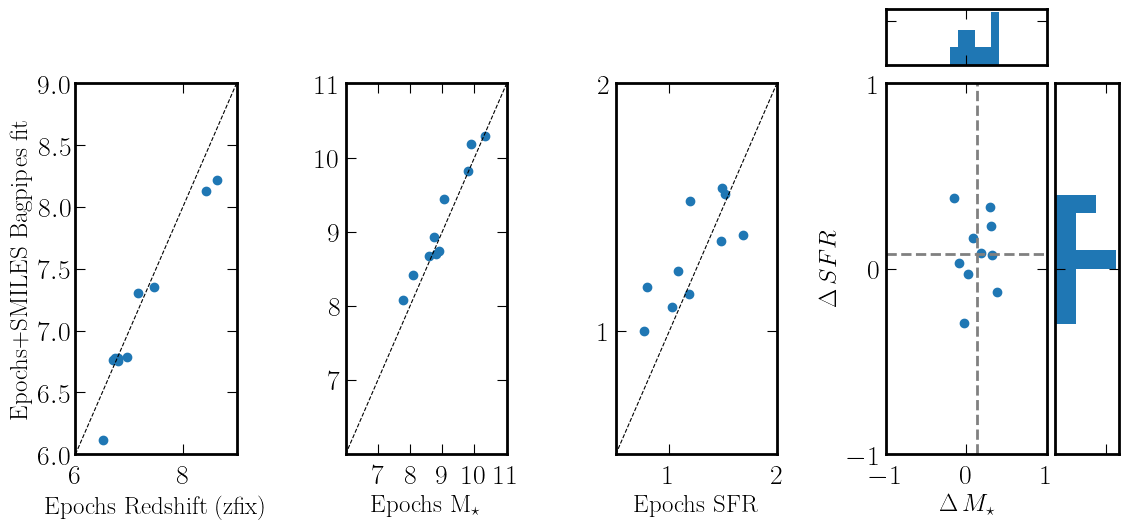

In [51]:
fig, ax = plt.subplots(1,4, figsize = (12,6))
ax[0].scatter(
    epochs_smiles_astro["zbest_epochs"],
    df["redshift_Q50"]
)
ax[0].set_xlim([6.0, 9.0])
ax[0].set_ylim([6.0, 9.0])
# ax[0].set_xticks([7,8,9])
# ax[0].set_yticks([7,8,9])

ax[1].scatter(
    epochs_smiles_astro["epochs_stellar_mass_zgauss"],
    np.log10(df["stellar_mass_Q50"])
)
ax[1].set_xlim([6.0, 11.0])
ax[1].set_ylim([6.0, 11.0])
ax[1].set_xticks([7,8,9,10,11])
ax[1].set_yticks([7,8,9,10,11])

ax[2].scatter(
    np.log10(epochs_smiles_astro["epochs_sfr10_zgauss"]),
    np.log10(df["sfr10_Q50"])
)
ax[2].set_xlim([0.5, 2.0])
ax[2].set_ylim([0.5, 2.0])
ax[2].set_xticks([1,2])
ax[2].set_yticks([1,2])

ax[0].axline((0, 0), slope=1, color="k", lw=0.8, ls="--")
ax[1].axline((0, 0), slope=1, color="k", lw=0.8, ls="--")
ax[2].axline((0, 0), slope=1, color="k", lw=0.8, ls="--")

ax[3].scatter(
    np.log10(df["stellar_mass_Q50"]) - epochs_smiles_astro["epochs_stellar_mass_zgauss"],
    np.log10(df["sfr10_Q50"]) - np.log10(epochs_smiles_astro["epochs_sfr10_zgauss"])
)
ax[3].axvline(np.median(np.log10(df["stellar_mass_Q50"]) - epochs_smiles_astro["epochs_stellar_mass_zgauss"]), ls = "--", color = "grey")
ax[3].axhline(np.median(np.log10(df["sfr10_Q50"]) - np.log10(epochs_smiles_astro["epochs_sfr10_zgauss"])), ls = "--", color = "grey")
ax[3].set_xlim([-1, 1.0])
ax[3].set_ylim([-1, 1.0])
ax[3].set_xticks([-1,0,1])
ax[3].set_yticks([-1,0,1])
ax[3].set_xlabel("$\\Delta \\, M_{\\star}$")
ax[3].set_ylabel("$\\Delta \\, SFR$")
ax_histx = ax[3].inset_axes([0, 1.05, 1, 0.15], sharex=ax[3])
ax_histy = ax[3].inset_axes([1.05, 0, 0.4, 1.0], sharey=ax[3])
ax_histx.tick_params(axis="both", labelleft=False, labelbottom=False)
ax_histy.tick_params(axis="both", labelleft=False, labelbottom=False)
ax_histx.hist(np.log10(df["stellar_mass_Q50"]) - epochs_smiles_astro["epochs_stellar_mass_zgauss"], bins=np.arange(-1,1,0.1))
ax_histy.hist(np.log10(df["sfr10_Q50"]) - np.log10(epochs_smiles_astro["epochs_sfr10_zgauss"]), bins=np.arange(-1,1,0.1), orientation='horizontal')

# ax[3].set_xlim([6.0, 11.0])
# ax[3].set_ylim([6.0, 11.0])
# ax[3].set_xticks([7,8,9,10,11])
# ax[3].set_yticks([7,8,9,10,11])

ax[0].set_ylabel("Epochs+SMILES Bagpipes fit")

ax[0].set_xlabel("Epochs Redshift (zfix)")
ax[1].set_xlabel("Epochs M$_{\\star}$")
ax[2].set_xlabel("Epochs SFR")

fig.tight_layout()
fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/epochs_smiles_compare_astro.pdf",
    bbox_inches="tight", dpi = 240
)

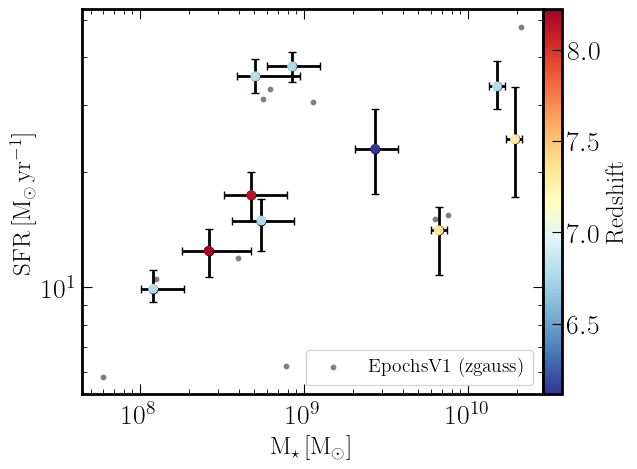

In [52]:
fig, ax = plt.subplots(1,1, figsize = (7,5))
ax.scatter(
    10**epochs_smiles_astro["epochs_stellar_mass_zgauss"],
    epochs_smiles_astro["epochs_sfr10_zgauss"],
    color = "grey", 
    label = "EpochsV1 (zgauss)",
    s = 10
)
sc = ax.scatter(
    df["stellar_mass_Q50"],
    df["sfr10_Q50"],
    c=df["redshift_Q50"],
    zorder = 200, 
    cmap = "RdYlBu_r"
)
ax.errorbar(
    df["stellar_mass_Q50"],
    df["sfr10_Q50"],
    xerr = [df["stellar_mass_Q50"]-df["stellar_mass_Q16"],df["stellar_mass_Q84"]-df["stellar_mass_Q50"]],
    yerr = [df["sfr10_Q50"]-df["sfr10_Q16"],df["sfr10_Q84"]-df["sfr10_Q50"]], 
    ls = "", 
    fmt = "o",
    capsize = 3.0,
    markeredgecolor = "black",
    markerfacecolor = "none",
    ecolor = "black",
    zorder = 1
)
fig.colorbar(sc, ax=ax, label="Redshift", pad = 0)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("$\\mathrm{ M_{\\star} \\, [M_{\\odot}] }$") 
ax.set_ylabel("$\\mathrm{ SFR \\, [M_{\\odot} \\, yr^{-1}] }$") 

ax.legend(fontsize = 14)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/epochs_smiles_sfr10_mstar.pdf",
    bbox_inches="tight", dpi = 240
)

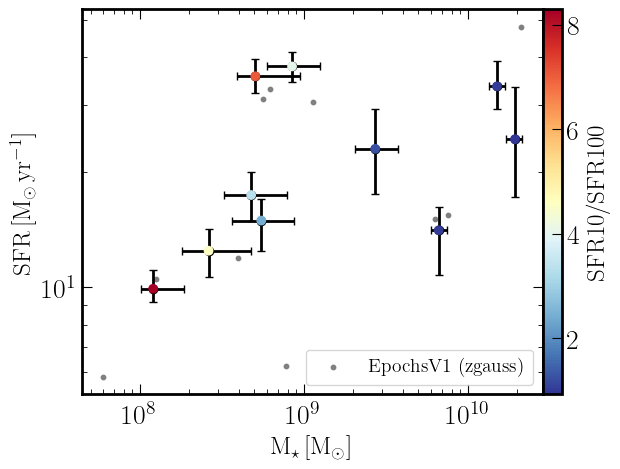

In [53]:
fig, ax = plt.subplots(1,1, figsize = (7,5))
ax.scatter(
    10**epochs_smiles_astro["epochs_stellar_mass_zgauss"],
    epochs_smiles_astro["epochs_sfr10_zgauss"],
    color = "grey", 
    label = "EpochsV1 (zgauss)",
    s = 10
)
sc = ax.scatter(
    df["stellar_mass_Q50"],
    df["sfr10_Q50"],
    c=df["burstiness_Q50"],
    zorder = 200, 
    cmap = "RdYlBu_r"
)
ax.errorbar(
    df["stellar_mass_Q50"],
    df["sfr10_Q50"],
    xerr = [df["stellar_mass_Q50"]-df["stellar_mass_Q16"],df["stellar_mass_Q84"]-df["stellar_mass_Q50"]],
    yerr = [df["sfr10_Q50"]-df["sfr10_Q16"],df["sfr10_Q84"]-df["sfr10_Q50"]], 
    ls = "", 
    fmt = "o",
    capsize = 3.0,
    markeredgecolor = "black",
    markerfacecolor = "none",
    ecolor = "black",
    zorder = 1
)
fig.colorbar(sc, ax=ax, label="SFR10/SFR100", pad = 0)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("$\\mathrm{ M_{\\star} \\, [M_{\\odot}] }$") 
ax.set_ylabel("$\\mathrm{ SFR \\, [M_{\\odot} \\, yr^{-1}] }$") 

ax.legend(fontsize = 14)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/epochs_smiles_sfr10_mstar_burstiness.pdf",
    bbox_inches="tight", dpi = 240
)

In [29]:
print(df)

    id  redshift_Q16  redshift_Q50  redshift_Q84  stellar_mass_Q16  \
0    0      6.025887      6.132743      6.327653      2.091220e+09   
1    1      6.394608      6.466736      6.537694      9.866375e+07   
2    2      6.640849      6.703233      6.731703      1.677894e+08   
3    3      6.628740      6.663666      6.702056      7.953239e+07   
4    4      6.668128      6.709607      6.762580      3.543652e+07   
5    5      6.700381      6.750159      6.808446      3.165044e+07   
6    6      6.674185      6.698394      6.725135      5.129296e+07   
7    7      6.704317      6.733186      6.780200      2.240085e+07   
8    8      6.734168      6.762294      6.800829      5.995748e+08   
9    9      6.718446      6.782168      6.843371      1.347874e+10   
10  10      0.941218      1.065625      1.092446      2.322979e+06   
11  11      6.759064      6.778026      6.802004      1.007683e+08   
12  12      6.725372      6.755848      6.793922      3.574224e+08   
13  13      6.478710


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/1.h5



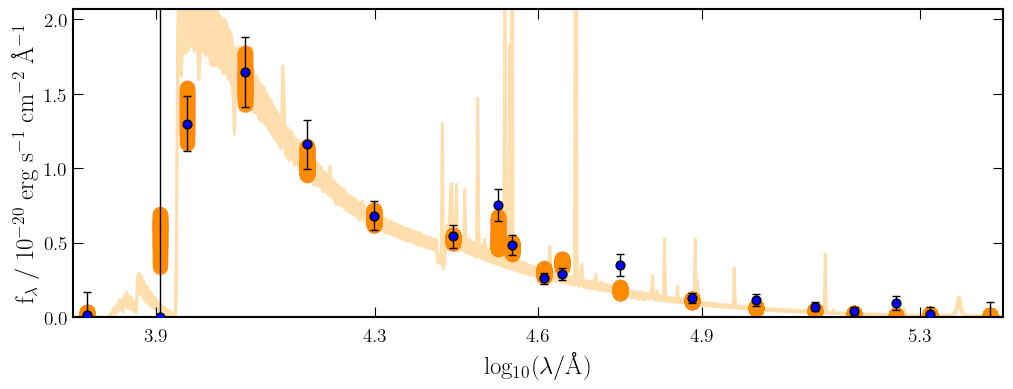

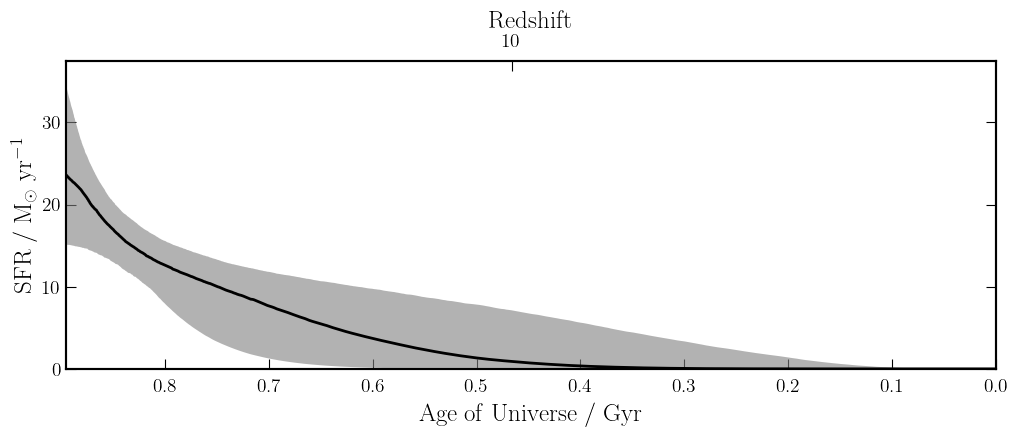

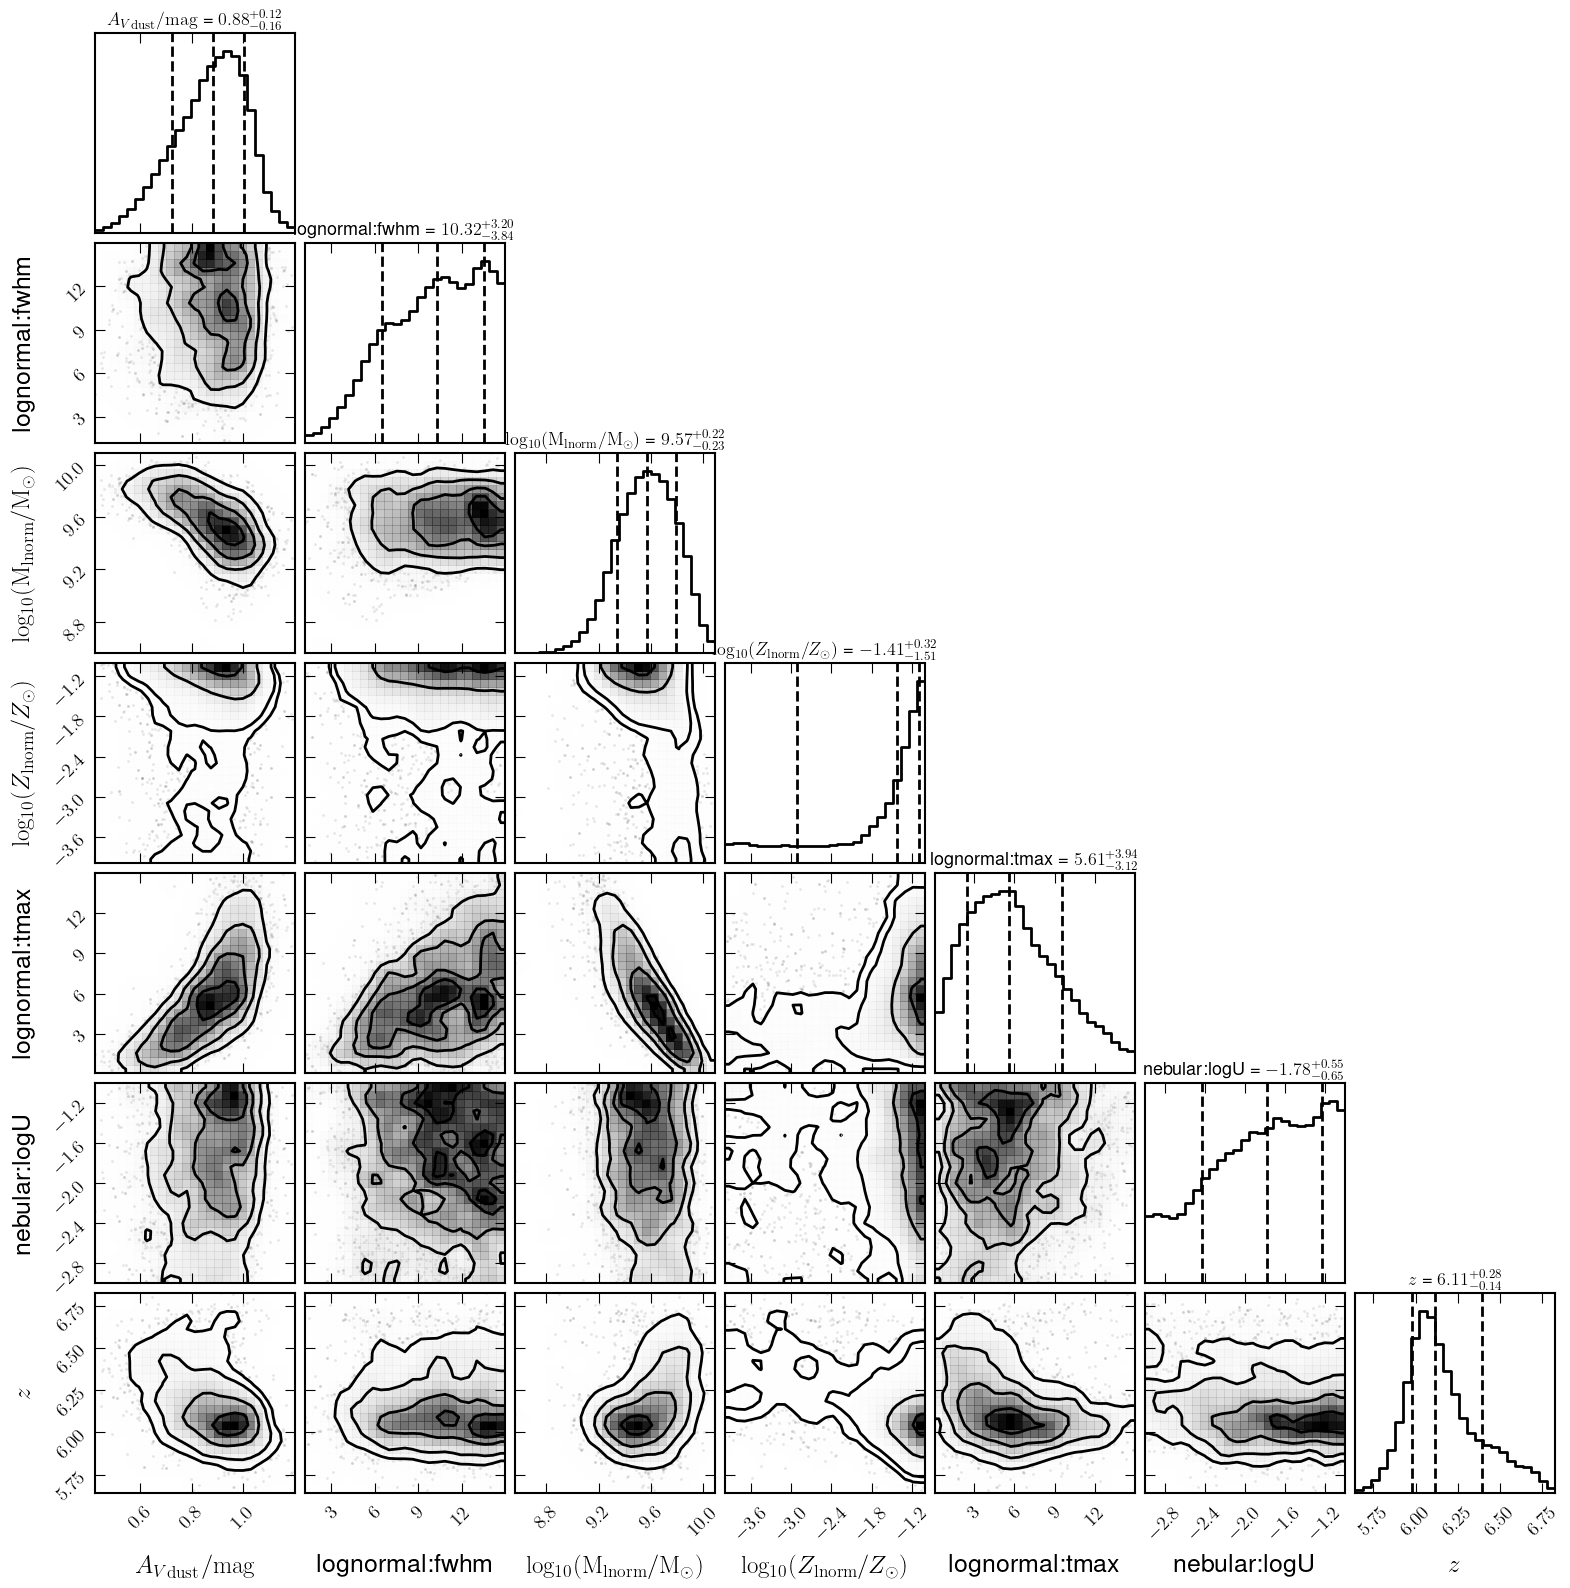

In [55]:
ID = 1
galaxy = pipes.galaxy(str(ID), lambda x: load_object(x, cat), spectrum_exists=False, filt_list=goodss_filt_list)
fit = pipes.fit(galaxy, fit_instructions, run = "epochs_smiles_2asec_match_fiducial_zfree", n_posterior=2000)

fig,ax = fit.plot_spectrum_posterior(save=False, show=True)
fig.savefig(
    f"/Users/jordan/Documents/Epochs/plots/epochs_smiles_fit_gal{ID}.pdf",
    bbox_inches="tight", dpi = 240
)
fig,ax = fit.plot_sfh_posterior(save=False, show=True)
fig.savefig(
    f"/Users/jordan/Documents/Epochs/plots/epochs_smiles_sfh_fit_gal{ID}.pdf",
    bbox_inches="tight", dpi = 240
)
fig = fit.plot_corner(save=False, show=True)
fig.savefig(
    f"/Users/jordan/Documents/Epochs/plots/epochs_smiles_corner_fit_gal{ID}.pdf",
    bbox_inches="tight", dpi = 240
)


Results loaded from pipes/posterior/epochs_smiles_2asec_match_fiducial_zfree/15.h5



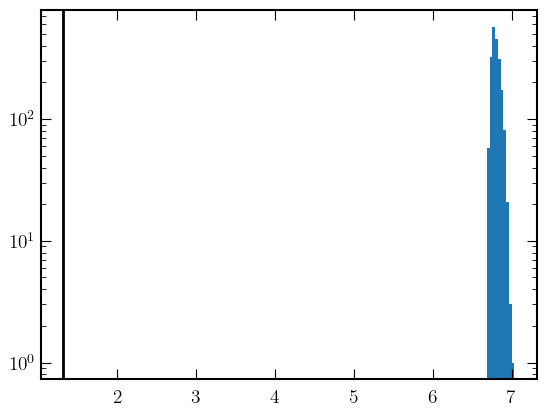

In [21]:
ID = 15
galaxy = pipes.galaxy(str(ID), lambda x: load_object(x, cat), spectrum_exists=False, filt_list=goodss_filt_list)
fit = pipes.fit(galaxy, fit_instructions, run = "epochs_smiles_2asec_match_fiducial_zfree", n_posterior=2000)

plt.hist( fit.posterior.samples["redshift"] )
plt.yscale("log")
# plt.axvline(2.5762)
plt.axvline(1.3167, color = "black")